In [ ]:
# import pandas as pd

# # Load the Excel file
# input_path = 'Human_Eval_dataset.xlsx'  # Replace with your actual file path
# df = pd.read_excel(input_path)

# # Duplicate each row 15 times
# duplicated_df = df.loc[df.index.repeat(15)].reset_index(drop=True)

# # Save the new DataFrame to a new Excel file
# output_path = 'duplicated_file.xlsx'
# duplicated_df.to_excel(output_path, index=False)

# print(f"Duplicated file saved to {output_path}")


import pandas as pd

# Load the duplicated Excel file
file_path = 'duplicated_file.xlsx'
df = pd.read_excel(file_path)

# Add 4 new columns with default/empty values
df['answer_type'] = ''
df['codeBert_score'] = ''
df['graphCodebert_score'] = ''
df['codeT5_score'] = ''

# Save the updated DataFrame back to Excel
df.to_excel(file_path, index=False)

print(f"New columns added and file saved to {file_path}")


Duplicated file saved to duplicated_file.xlsx


In [ ]:
import requests

# Base URL for the new API
url = "https://clinicaltrials.gov/api/v2/studies"

# Define parameters for search query
params = {
    "query.term": "COVID-19 vaccine AND Recruiting AND United States",
    "pageSize": 5  # You can increase this number to get more results
}

# Send the GET request
response = requests.get(url, params=params)

# Check for successful response
if response.status_code == 200:
    data = response.json()
    studies = data.get('studies', [])

    if not studies:
        print("No studies found.")
    else:
        for i, study in enumerate(studies, 1):
            title = study.get('protocolSection', {}).get('identificationModule', {}).get('officialTitle', 'N/A')
            nct_id = study.get('protocolSection', {}).get('identificationModule', {}).get('nctId', 'N/A')
            status = study.get('protocolSection', {}).get('statusModule', {}).get('overallStatus', 'N/A')

            print(f"{i}. {title}\n   NCT ID: {nct_id}\n   Status: {status}\n")
else:
    print(f"Failed to fetch data. Status code: {response.status_code}")




1. COVID-19 Transmission and Morbidity in Malawi
   NCT ID: NCT05973084
   Status: RECRUITING

2. Pfizer-BioNTech COVID-19 BNT162b2 Vaccine Effectiveness Study - Kaiser Permanente Southern California
   NCT ID: NCT04848584
   Status: RECRUITING

3. The Impact of COVID-19 on Maternal and Neonatal Outcomes
   NCT ID: NCT05197621
   Status: RECRUITING

4. Low Interventional Cohort Study of Myocarditis/Pericarditis Associated With COMIRNATY in Persons Less Than 21 Years of Age
   NCT ID: NCT05295290
   Status: RECRUITING

5. A Phase 2, Randomized, Observer-blind, Active-control Study to Evaluate the Immunogenicity, Reactogenicity, and Safety of mRNA-1083 (Influenza and COVID-19) Vaccine in Adults ≥18 to <65 Years of Age
   NCT ID: NCT06864143
   Status: RECRUITING



In [ ]:
import requests

# Define API endpoint and parameters
url = "https://clinicaltrials.gov/api/v2/studies"

params = {
    "query.term": "HIV",  # Search for HIV-related studies
    "pageSize": 100        # Adjust this for more or fewer results
}

# Send the GET request
response = requests.get(url, params=params)

# Check for a successful response
if response.status_code == 200:
    data = response.json()
    studies = data.get("studies", [])

    if not studies:
        print("No HIV-related studies found.")
    else:
        for i, study in enumerate(studies, 1):
            protocol = study.get("protocolSection", {})
            title = protocol.get("identificationModule", {}).get("officialTitle", "N/A")
            nct_id = protocol.get("identificationModule", {}).get("nctId", "N/A")

            interventions = protocol.get("armsInterventionsModule", {}).get("interventions", [])
            intervention_list = [interv.get("name", "N/A") for interv in interventions]

            print(f"{i}. {title}\n   NCT ID: {nct_id}")
            print("   Interventions:")
            for interv in intervention_list:
                print(f"     - {interv}")
            print()
else:
    print(f"Failed to fetch data. Status code: {response.status_code}")


1. Hepatitis B and HIV Co-Infection in Uganda
   NCT ID: NCT00782158
   Interventions:

2. Doxycycline Prophylaxis or Incentive Payments to Reduce Incident Syphilis Among HIV- Infected Men Who Have Sex With Men Who Continue to Engage in High Risk Sex: A Randomized, Controlled Pilot Study
   NCT ID: NCT02257658
   Interventions:
     - Doxycycyline
     - Incentive

3. An Extension Protocol for Subjects Who Successfully Completed PRO140_CD02 Study
   NCT ID: NCT02990858
   Interventions:
     - PRO 140 SC injections

4. Trial of Zinc and HIV Progression in Children
   NCT ID: NCT00446758
   Interventions:
     - Zinc

5. Eliminating Hepatitis C Transmission by Enhancing Care and Treatment Among HIV Co-infected Individuals: The Co-EC Study
   NCT ID: NCT02786758
   Interventions:

6. Accuracy of Ethnicity Recording in MSM Patients With HIV of Non-White Ethnicity in London
   NCT ID: NCT01277458
   Interventions:

7. Randomized, Open-label Controlled Trial of Daily Trimethoprim-sulfametho

In [ ]:
import requests
import pandas as pd

# API base endpoint
url = "https://clinicaltrials.gov/api/v2/studies"

# Parameters for the API request
params = {
    "query.term": "HIV",
    "pageSize": 200  # Increase for more records (max ~1000 per page)
}

# Send request
response = requests.get(url, params=params)

# Process response
if response.status_code == 200:
    studies = response.json().get("studies", [])
    results = []

    for study in studies:
        protocol = study.get("protocolSection", {})

        title = protocol.get("identificationModule", {}).get("officialTitle", "N/A")
        nct_id = protocol.get("identificationModule", {}).get("nctId", "N/A")
        summary = protocol.get("descriptionModule", {}).get("briefSummary", "N/A")
        study_type = protocol.get("designModule", {}).get("studyType", "N/A")
        phase = protocol.get("designModule", {}).get("phase", "N/A")
        status = protocol.get("statusModule", {}).get("overallStatus", "N/A")
        start_date = protocol.get("statusModule", {}).get("startDateStruct", {}).get("date", "N/A")
        completion_date = protocol.get("statusModule", {}).get("completionDateStruct", {}).get("date", "N/A")
        sponsor = protocol.get("sponsorCollaboratorsModule", {}).get("leadSponsor", {}).get("name", "N/A")

        # Interventions
        interventions = protocol.get("armsInterventionsModule", {}).get("interventions", [])
        intervention_list = [i.get("name", "N/A") for i in interventions]
        intervention_str = "; ".join(intervention_list) if intervention_list else "N/A"

        # Locations
        locations = protocol.get("contactsLocationsModule", {}).get("locations", [])
        location_list = [loc.get("locationFacility", "N/A") for loc in locations]
        location_str = "; ".join(location_list) if location_list else "N/A"

        # Append all extracted data to results list
        results.append({
            "NCT ID": nct_id,
            "Title": title,
            "Summary": summary,
            "Study Type": study_type,
            "Phase": phase,
            "Status": status,
            "Start Date": start_date,
            "Completion Date": completion_date,
            "Sponsor": sponsor,
            "Interventions": intervention_str,
            "Locations": location_str
        })

    # Convert to DataFrame and save to CSV
    df = pd.DataFrame(results)
    df.to_csv("hiv_clinical_trials_dataset.csv", index=False)
    print("✅ Dataset saved as 'hiv_clinical_trials_dataset.csv'")
else:
    print(f"❌ Failed to fetch data. Status code: {response.status_code}")


✅ Dataset saved as 'hiv_clinical_trials_dataset.csv'


In [ ]:
import requests
import pandas as pd

# API base URL
url = "https://clinicaltrials.gov/api/v2/studies"

# API parameters
params = {
    "query.term": "HIV",
    "pageSize": 20  # Adjust as needed
}

# Send request to ClinicalTrials.gov
response = requests.get(url, params=params)

# Check for successful response
if response.status_code == 200:
    studies = response.json().get("studies", [])
    results = []

    for study in studies:
        protocol = study.get("protocolSection", {})

        title = protocol.get("identificationModule", {}).get("officialTitle", "N/A")
        nct_id = protocol.get("identificationModule", {}).get("nctId", "N/A")
        summary = protocol.get("descriptionModule", {}).get("briefSummary", "N/A")
        study_type = protocol.get("designModule", {}).get("studyType", "N/A")
        phase = protocol.get("designModule", {}).get("phase", "N/A")
        status = protocol.get("statusModule", {}).get("overallStatus", "N/A")
        start_date = protocol.get("statusModule", {}).get("startDateStruct", {}).get("date", "N/A")
        completion_date = protocol.get("statusModule", {}).get("completionDateStruct", {}).get("date", "N/A")
        sponsor = protocol.get("sponsorCollaboratorsModule", {}).get("leadSponsor", {}).get("name", "N/A")

        # Interventions
        interventions = protocol.get("armsInterventionsModule", {}).get("interventions", [])
        intervention_list = [i.get("name", "N/A") for i in interventions]
        intervention_str = "; ".join(intervention_list) if intervention_list else "N/A"

        # Locations (site names)
        locations = protocol.get("contactsLocationsModule", {}).get("locations", [])
        location_list = [loc.get("locationFacility", "N/A") for loc in locations]
        location_str = "; ".join(location_list) if location_list else "N/A"

        # Location countries
        countries = protocol.get("contactsLocationsModule", {}).get("locationCountries", [])
        country_str = "; ".join(countries) if countries else "N/A"

        # Append all data
        results.append({
            "NCT ID": nct_id,
            "Title": title,
            "Summary": summary,
            "Study Type": study_type,
            "Phase": phase,
            "Status": status,
            "Start Date": start_date,
            "Completion Date": completion_date,
            "Sponsor": sponsor,
            "Interventions": intervention_str,
            "Locations": location_str,
            "Location Countries": country_str
        })

    # Save as CSV
    df = pd.DataFrame(results)
    df.to_csv("hiv_clinical_trials_with_countries.csv", index=False)
    print("✅ Saved as 'hiv_clinical_trials_with_countries.csv'")
else:
    print(f"❌ Failed to fetch data. Status code: {response.status_code}")


✅ Saved as 'hiv_clinical_trials_with_countries.csv'


In [ ]:
import requests
import json
import pandas as pd

BASE_URL = "https://clinicaltrials.gov/api/v2/studies"
page_size = 100
page_token = None
all_studies = []

print("🔄 Fetching all HIV clinical trial data...")

# Step 1: Fetch all studies with pagination
while True:
    params = {
        "query.term": "HIV",
        "pageSize": page_size
    }
    if page_token:
        params["pageToken"] = page_token

    response = requests.get(BASE_URL, params=params)
    if response.status_code != 200:
        print(f"❌ Failed to fetch data. Status code: {response.status_code}")
        break

    data = response.json()
    studies = data.get("studies", [])
    all_studies.extend(studies)

    # Progress
    print(f"✅ Fetched {len(all_studies)} studies so far...")

    # Next page
    page_token = data.get("nextPageToken")
    if not page_token:
        break

print(f"🎉 Finished fetching! Total studies: {len(all_studies)}")

# Step 2: Save raw JSON (optional)
with open("hiv_clinical_trials_full_raw.json", "w") as f:
    json.dump(all_studies, f, indent=4)
print("💾 Full raw JSON saved as 'hiv_clinical_trials_full_raw.json'")

# Step 3: Flatten metadata, results, and adverse events
flattened_data = []
for study in all_studies:
    protocol = study.get("protocolSection", {})
    results_module = study.get("resultsSection", {})

    flat = {
        "NCT ID": protocol.get("identificationModule", {}).get("nctId", "N/A"),
        "Brief Title": protocol.get("identificationModule", {}).get("briefTitle", "N/A"),
        "Official Title": protocol.get("identificationModule", {}).get("officialTitle", "N/A"),
        "Acronym": protocol.get("identificationModule", {}).get("acronym", "N/A"),
        "Study Type": protocol.get("designModule", {}).get("studyType", "N/A"),
        "Phase": protocol.get("designModule", {}).get("phase", "N/A"),
        "Intervention Model": protocol.get("designModule", {}).get("interventionModel", "N/A"),
        "Primary Purpose": protocol.get("designModule", {}).get("primaryPurpose", "N/A"),
        "Overall Status": protocol.get("statusModule", {}).get("overallStatus", "N/A"),
        "Start Date": protocol.get("statusModule", {}).get("startDateStruct", {}).get("date", "N/A"),
        "Primary Completion Date": protocol.get("statusModule", {}).get("primaryCompletionDateStruct", {}).get("date", "N/A"),
        "Completion Date": protocol.get("statusModule", {}).get("completionDateStruct", {}).get("date", "N/A"),
        "Last Update Submit Date": protocol.get("statusModule", {}).get("lastUpdateSubmitDate", "N/A"),
        "Sponsor": protocol.get("sponsorCollaboratorsModule", {}).get("leadSponsor", {}).get("name", "N/A"),
        "Collaborators": "; ".join(
            [col.get("name", "N/A") for col in protocol.get("sponsorCollaboratorsModule", {}).get("collaborators", [])]
        ) or "N/A",
        "Brief Summary": protocol.get("descriptionModule", {}).get("briefSummary", "N/A"),
        "Detailed Description": protocol.get("descriptionModule", {}).get("detailedDescription", "N/A"),
    }

    # Interventions
    interventions = protocol.get("armsInterventionsModule", {}).get("interventions", [])
    flat["Interventions"] = "; ".join([i.get("name", "N/A") for i in interventions]) or "N/A"

    # Locations and Countries
    contacts = protocol.get("contactsLocationsModule", {})
    locations = [loc.get("locationFacility", "N/A") for loc in contacts.get("locations", [])]
    flat["Locations"] = "; ".join(locations) or "N/A"
    flat["Countries"] = "; ".join(contacts.get("locationCountries", [])) or "N/A"

    # Eligibility
    eligibility = protocol.get("eligibilityModule", {})
    flat["Eligibility Criteria"] = eligibility.get("eligibilityCriteria", "N/A")
    flat["Gender"] = eligibility.get("sex", "N/A")
    flat["Minimum Age"] = eligibility.get("minimumAge", "N/A")
    flat["Maximum Age"] = eligibility.get("maximumAge", "N/A")
    flat["Healthy Volunteers"] = eligibility.get("healthyVolunteers", "N/A")

    # -------------------------
    # Results Section
    # -------------------------
    if results_module:
        # Outcomes
        outcomes = []
        for outcome in results_module.get("outcomesModule", {}).get("primaryOutcomes", []):
            outcomes.append("Primary: " + outcome.get("measure", "N/A"))
        for outcome in results_module.get("outcomesModule", {}).get("secondaryOutcomes", []):
            outcomes.append("Secondary: " + outcome.get("measure", "N/A"))
        flat["Posted Outcomes"] = "; ".join(outcomes) or "N/A"

        # Adverse Events
        adverse_events_module = results_module.get("adverseEventsModule", {})
        serious_events = []
        for event in adverse_events_module.get("seriousEvents", []):
            term = event.get("term", "N/A")
            serious_events.append(term)
        flat["Serious Adverse Events"] = "; ".join(serious_events) or "N/A"

        other_events = []
        for event in adverse_events_module.get("otherEvents", []):
            term = event.get("term", "N/A")
            other_events.append(term)
        flat["Other Adverse Events"] = "; ".join(other_events) or "N/A"
    else:
        flat["Posted Outcomes"] = "N/A"
        flat["Serious Adverse Events"] = "N/A"
        flat["Other Adverse Events"] = "N/A"

    flattened_data.append(flat)

# Step 4: Save to CSV
df = pd.DataFrame(flattened_data)
df.to_csv("hiv_clinical_trials_full_metadata_with_results.csv", index=False)
print("💾 Full metadata with results & adverse events saved as 'hiv_clinical_trials_full_metadata_with_results.csv'")


🔄 Fetching all HIV clinical trial data...
✅ Fetched 100 studies so far...
✅ Fetched 200 studies so far...
✅ Fetched 300 studies so far...
✅ Fetched 400 studies so far...
✅ Fetched 500 studies so far...
✅ Fetched 600 studies so far...
✅ Fetched 700 studies so far...
✅ Fetched 800 studies so far...
✅ Fetched 900 studies so far...
✅ Fetched 1000 studies so far...
✅ Fetched 1100 studies so far...
✅ Fetched 1200 studies so far...
✅ Fetched 1300 studies so far...
✅ Fetched 1400 studies so far...
✅ Fetched 1500 studies so far...
✅ Fetched 1600 studies so far...
✅ Fetched 1700 studies so far...
✅ Fetched 1800 studies so far...
✅ Fetched 1900 studies so far...
✅ Fetched 2000 studies so far...
✅ Fetched 2100 studies so far...
✅ Fetched 2200 studies so far...
✅ Fetched 2300 studies so far...
✅ Fetched 2400 studies so far...
✅ Fetched 2500 studies so far...
✅ Fetched 2600 studies so far...
✅ Fetched 2700 studies so far...
✅ Fetched 2800 studies so far...
✅ Fetched 2900 studies so far...
✅ Fetched 

In [ ]:
import pandas as pd

# Load the CSV file
file_path = "hiv_clinical_trials_full_metadata_with_results.csv"  # Change if different
df = pd.read_csv(file_path)

# View the shape (rows x columns)
print(f"Dataset has {df.shape[0]} rows and {df.shape[1]} columns.\n")

# View first 5 rows
print("🔹 First 5 rows:")
print(df.head())

# View column names
print("\n🔹 Column Names:")
print(df.columns.tolist())

# View summary info
print("\n🔹 Dataset Info:")
print(df.info())

# View missing data counts per column
print("\n🔹 Missing values per column:")
print(df.isnull().sum())

# Example: View all unique study types (Interventional/Observational)
print("\n🔹 Unique Study Types:")
print(df["Study Type"].unique())

# Example: Check top 10 countries conducting trials
if "Countries" in df.columns:
    country_counts = df["Countries"].value_counts().head(10)
    print("\n🔹 Top 10 countries with HIV trials:")
    print(country_counts)


Dataset has 12981 rows and 28 columns.

🔹 First 5 rows:
        NCT ID                                        Brief Title  \
0  NCT04291729  Evaluation of Ganovo （Danoprevir ） Combined Wi...   
1  NCT04562129  IL2 With Ipilimumab Followed by Nivolumab in S...   
2  NCT02961829  Multi Interventional Study Exploring HIV-1 Res...   
3  NCT00002380  The Safety and Effectiveness of Two Forms of S...   
4  NCT00223080                   HIV Vaccine Trial in Thai Adults   

                                      Official Title Acronym      Study Type  \
0  An Open Clinical Trial to Evaluate Ganovo（Dano...     NaN  INTERVENTIONAL   
1  A Phase II Study of High Dose Bolus IL2 in Com...     NaN  INTERVENTIONAL   
2  Multi Interventional Study Exploring HIV-1 Res...     NaN  INTERVENTIONAL   
3  A Phase I/II Pharmacokinetic and Safety Study ...     NaN  INTERVENTIONAL   
4  A Phase III Trial of Aventis Pasteur Live Reco...     NaN  INTERVENTIONAL   

   Phase  Intervention Model  Primary Purpose Ov

In [ ]:
import json
import pandas as pd

# Load JSON file
json_file = "hiv_clinical_trials_full_raw.json"  # Change to your file name
with open(json_file, "r") as f:
    data = json.load(f)

print(f"✅ Loaded {len(data)} studies from JSON.")

# Initialize lists for each sheet
main_data = []
interventions_data = []
locations_data = []
outcomes_data = []
serious_adverse_data = []
other_adverse_data = []

for study in data:
    nct_id = study.get("protocolSection", {}).get("identificationModule", {}).get("nctId", "N/A")
    protocol = study.get("protocolSection", {})
    results = study.get("resultsSection", {})

    # ----------------------
    # Main Metadata Row
    # ----------------------
    main_data.append({
        "NCT ID": nct_id,
        "Brief Title": protocol.get("identificationModule", {}).get("briefTitle", "N/A"),
        "Official Title": protocol.get("identificationModule", {}).get("officialTitle", "N/A"),
        "Study Type": protocol.get("designModule", {}).get("studyType", "N/A"),
        "Phase": protocol.get("designModule", {}).get("phase", "N/A"),
        "Overall Status": protocol.get("statusModule", {}).get("overallStatus", "N/A"),
        "Start Date": protocol.get("statusModule", {}).get("startDateStruct", {}).get("date", "N/A"),
        "Completion Date": protocol.get("statusModule", {}).get("completionDateStruct", {}).get("date", "N/A"),
        "Primary Completion Date": protocol.get("statusModule", {}).get("primaryCompletionDateStruct", {}).get("date", "N/A"),
        "Sponsor": protocol.get("sponsorCollaboratorsModule", {}).get("leadSponsor", {}).get("name", "N/A"),
        "Collaborators": "; ".join([col.get("name","N/A") for col in protocol.get("sponsorCollaboratorsModule", {}).get("collaborators", [])]) or "N/A",
        "Brief Summary": protocol.get("descriptionModule", {}).get("briefSummary", "N/A")
    })

    # ----------------------
    # Interventions Sheet
    # ----------------------
    interventions = protocol.get("armsInterventionsModule", {}).get("interventions", [])
    for iv in interventions:
        interventions_data.append({
            "NCT ID": nct_id,
            "Intervention Name": iv.get("name", "N/A"),
            "Type": iv.get("type", "N/A"),
            "Description": iv.get("description", "N/A")
        })

    # ----------------------
    # Locations Sheet
    # ----------------------
    locations = protocol.get("contactsLocationsModule", {}).get("locations", [])
    for loc in locations:
        locations_data.append({
            "NCT ID": nct_id,
            "Facility": loc.get("locationFacility", "N/A"),
            "City": loc.get("city", "N/A"),
            "State": loc.get("state", "N/A"),
            "Country": loc.get("country", "N/A")
        })

    # ----------------------
    # Outcomes Sheet
    # ----------------------
    outcomes_module = results.get("outcomesModule", {})
    for outcome in outcomes_module.get("primaryOutcomes", []):
        outcomes_data.append({
            "NCT ID": nct_id,
            "Type": "Primary",
            "Measure": outcome.get("measure", "N/A"),
            "Time Frame": outcome.get("timeFrame", "N/A"),
            "Description": outcome.get("description", "N/A")
        })
    for outcome in outcomes_module.get("secondaryOutcomes", []):
        outcomes_data.append({
            "NCT ID": nct_id,
            "Type": "Secondary",
            "Measure": outcome.get("measure", "N/A"),
            "Time Frame": outcome.get("timeFrame", "N/A"),
            "Description": outcome.get("description", "N/A")
        })

    # ----------------------
    # Adverse Events Sheet
    # ----------------------
    ae_module = results.get("adverseEventsModule", {})
    for event in ae_module.get("seriousEvents", []):
        serious_adverse_data.append({
            "NCT ID": nct_id,
            "Event Term": event.get("term", "N/A"),
            "Organ System": event.get("organSystem", "N/A"),
            "Frequency Threshold": ae_module.get("frequencyThreshold", "N/A")
        })
    for event in ae_module.get("otherEvents", []):
        other_adverse_data.append({
            "NCT ID": nct_id,
            "Event Term": event.get("term", "N/A"),
            "Organ System": event.get("organSystem", "N/A"),
            "Frequency Threshold": ae_module.get("frequencyThreshold", "N/A")
        })

# Convert all to DataFrames
df_main = pd.DataFrame(main_data).fillna("N/A")
df_interventions = pd.DataFrame(interventions_data).fillna("N/A")
df_locations = pd.DataFrame(locations_data).fillna("N/A")
df_outcomes = pd.DataFrame(outcomes_data).fillna("N/A")
df_serious_ae = pd.DataFrame(serious_adverse_data).fillna("N/A")
df_other_ae = pd.DataFrame(other_adverse_data).fillna("N/A")

# Save to Excel with multiple sheets
output_file = "hiv_clinical_trials_full_exploded.xlsx"
with pd.ExcelWriter(output_file, engine="xlsxwriter") as writer:
    df_main.to_excel(writer, sheet_name="Main_Metadata", index=False)
    df_interventions.to_excel(writer, sheet_name="Interventions", index=False)
    df_locations.to_excel(writer, sheet_name="Locations", index=False)
    df_outcomes.to_excel(writer, sheet_name="Outcomes", index=False)
    df_serious_ae.to_excel(writer, sheet_name="Serious_AdverseEvents", index=False)
    df_other_ae.to_excel(writer, sheet_name="Other_AdverseEvents", index=False)

print(f"💾 Excel file saved as '{output_file}' with fully exploded nested data.")


FileNotFoundError: [Errno 2] No such file or directory: 'hiv_clinical_trials_full_raw.json'

In [ ]:
import requests
import json
import pandas as pd

# -------------------------------
# Step 1: Fetch HIV Clinical Trials Data
# -------------------------------
BASE_URL = "https://clinicaltrials.gov/api/v2/studies"
page_size = 100
page_token = None
all_studies = []

print("🔄 Fetching all HIV clinical trial data...")

while True:
    params = {
        "query.term": "HIV",
        "pageSize": page_size
    }
    if page_token:
        params["pageToken"] = page_token

    response = requests.get(BASE_URL, params=params)
    if response.status_code != 200:
        print(f"❌ Failed to fetch data. Status code: {response.status_code}")
        break

    data = response.json()
    studies = data.get("studies", [])
    all_studies.extend(studies)

    print(f"✅ Fetched {len(all_studies)} studies so far...")

    page_token = data.get("nextPageToken")
    if not page_token:
        break

print(f"🎉 Finished fetching! Total studies: {len(all_studies)}")

# -------------------------------
# Step 2: Save Raw JSON
# -------------------------------
json_file = "hiv_clinical_trials_full_raw.json"
with open(json_file, "w") as f:
    json.dump(all_studies, f, indent=4)
print(f"💾 Raw JSON saved as '{json_file}'")

# -------------------------------
# Step 3: Convert to Fully Exploded Excel
# -------------------------------
main_data = []
interventions_data = []
locations_data = []
outcomes_data = []
serious_adverse_data = []
other_adverse_data = []

for study in all_studies:
    protocol = study.get("protocolSection", {})
    results = study.get("resultsSection", {})
    nct_id = protocol.get("identificationModule", {}).get("nctId", "N/A")

    # --- Main Metadata ---
    main_data.append({
        "NCT ID": nct_id,
        "Brief Title": protocol.get("identificationModule", {}).get("briefTitle", "N/A"),
        "Official Title": protocol.get("identificationModule", {}).get("officialTitle", "N/A"),
        "Study Type": protocol.get("designModule", {}).get("studyType", "N/A"),
        "Phase": protocol.get("designModule", {}).get("phase", "N/A"),
        "Overall Status": protocol.get("statusModule", {}).get("overallStatus", "N/A"),
        "Start Date": protocol.get("statusModule", {}).get("startDateStruct", {}).get("date", "N/A"),
        "Primary Completion Date": protocol.get("statusModule", {}).get("primaryCompletionDateStruct", {}).get("date", "N/A"),
        "Completion Date": protocol.get("statusModule", {}).get("completionDateStruct", {}).get("date", "N/A"),
        "Sponsor": protocol.get("sponsorCollaboratorsModule", {}).get("leadSponsor", {}).get("name", "N/A"),
        "Collaborators": "; ".join([col.get("name","N/A") for col in protocol.get("sponsorCollaboratorsModule", {}).get("collaborators", [])]) or "N/A",
        "Brief Summary": protocol.get("descriptionModule", {}).get("briefSummary", "N/A")
    })

    # --- Interventions ---
    for iv in protocol.get("armsInterventionsModule", {}).get("interventions", []):
        interventions_data.append({
            "NCT ID": nct_id,
            "Intervention Name": iv.get("name", "N/A"),
            "Type": iv.get("type", "N/A"),
            "Description": iv.get("description", "N/A")
        })

    # --- Locations ---
    for loc in protocol.get("contactsLocationsModule", {}).get("locations", []):
        locations_data.append({
            "NCT ID": nct_id,
            "Facility": loc.get("locationFacility", "N/A"),
            "City": loc.get("city", "N/A"),
            "State": loc.get("state", "N/A"),
            "Country": loc.get("country", "N/A")
        })

    # --- Outcomes ---
    outcomes_module = results.get("outcomesModule", {})
    for outcome in outcomes_module.get("primaryOutcomes", []):
        outcomes_data.append({
            "NCT ID": nct_id,
            "Type": "Primary",
            "Measure": outcome.get("measure", "N/A"),
            "Time Frame": outcome.get("timeFrame", "N/A"),
            "Description": outcome.get("description", "N/A")
        })
    for outcome in outcomes_module.get("secondaryOutcomes", []):
        outcomes_data.append({
            "NCT ID": nct_id,
            "Type": "Secondary",
            "Measure": outcome.get("measure", "N/A"),
            "Time Frame": outcome.get("timeFrame", "N/A"),
            "Description": outcome.get("description", "N/A")
        })

    # --- Adverse Events ---
    ae_module = results.get("adverseEventsModule", {})
    for event in ae_module.get("seriousEvents", []):
        serious_adverse_data.append({
            "NCT ID": nct_id,
            "Event Term": event.get("term", "N/A"),
            "Organ System": event.get("organSystem", "N/A"),
            "Frequency Threshold": ae_module.get("frequencyThreshold", "N/A")
        })
    for event in ae_module.get("otherEvents", []):
        other_adverse_data.append({
            "NCT ID": nct_id,
            "Event Term": event.get("term", "N/A"),
            "Organ System": event.get("organSystem", "N/A"),
            "Frequency Threshold": ae_module.get("frequencyThreshold", "N/A")
        })

# Convert lists to DataFrames
df_main = pd.DataFrame(main_data).fillna("N/A")
df_interventions = pd.DataFrame(interventions_data).fillna("N/A")
df_locations = pd.DataFrame(locations_data).fillna("N/A")
df_outcomes = pd.DataFrame(outcomes_data).fillna("N/A")
df_serious_ae = pd.DataFrame(serious_adverse_data).fillna("N/A")
df_other_ae = pd.DataFrame(other_adverse_data).fillna("N/A")

# Save to Excel with multiple sheets
output_file = "hiv_clinical_trials_full_exploded.xlsx"
with pd.ExcelWriter(output_file, engine="xlsxwriter") as writer:
    df_main.to_excel(writer, sheet_name="Main_Metadata", index=False)
    df_interventions.to_excel(writer, sheet_name="Interventions", index=False)
    df_locations.to_excel(writer, sheet_name="Locations", index=False)
    df_outcomes.to_excel(writer, sheet_name="Outcomes", index=False)
    df_serious_ae.to_excel(writer, sheet_name="Serious_AdverseEvents", index=False)
    df_other_ae.to_excel(writer, sheet_name="Other_AdverseEvents", index=False)

print(f"💾 Full dataset saved as '{output_file}' with 6 sheets.")


🔄 Fetching all HIV clinical trial data...
✅ Fetched 100 studies so far...
✅ Fetched 200 studies so far...
✅ Fetched 300 studies so far...
✅ Fetched 400 studies so far...
✅ Fetched 500 studies so far...
✅ Fetched 600 studies so far...
✅ Fetched 700 studies so far...
✅ Fetched 800 studies so far...
✅ Fetched 900 studies so far...
✅ Fetched 1000 studies so far...
✅ Fetched 1100 studies so far...
✅ Fetched 1200 studies so far...
✅ Fetched 1300 studies so far...
✅ Fetched 1400 studies so far...
✅ Fetched 1500 studies so far...
✅ Fetched 1600 studies so far...
✅ Fetched 1700 studies so far...
✅ Fetched 1800 studies so far...
✅ Fetched 1900 studies so far...
✅ Fetched 2000 studies so far...
✅ Fetched 2100 studies so far...
✅ Fetched 2200 studies so far...
✅ Fetched 2300 studies so far...
✅ Fetched 2400 studies so far...
✅ Fetched 2500 studies so far...
✅ Fetched 2600 studies so far...
✅ Fetched 2700 studies so far...
✅ Fetched 2800 studies so far...
✅ Fetched 2900 studies so far...
✅ Fetched 

In [ ]:
import pandas as pd

# Load the Excel file
file_path = "hiv_clinical_trials_full_exploded.xlsx"  # Update if needed

# Load the Locations sheet
df_locations = pd.read_excel(file_path, sheet_name="Locations")

# Filter rows where Country is Nigeria (case-insensitive)
nigeria_trials = df_locations[df_locations["Country"].str.lower() == "nigeria"]

# Optional: Merge with Main Metadata for more info about each trial
df_main = pd.read_excel(file_path, sheet_name="Main_Metadata")
nigeria_full = nigeria_trials.merge(df_main, on="NCT ID", how="left")

# Save the Nigeria trials to a separate Excel file
nigeria_full.to_excel("hiv_trials_in_nigeria.xlsx", index=False)

print(f"✅ Extracted {nigeria_full.shape[0]} rows for trials conducted in Nigeria.")
print("Preview:")
print(nigeria_full.head())


✅ Extracted 137 rows for trials conducted in Nigeria.
Preview:
        NCT ID  Facility     City        State  Country  \
0  NCT02269462       NaN   Adikpo  Benue State  Nigeria   
1  NCT02269462       NaN  Makurdi  Benue State  Nigeria   
2  NCT02269462       NaN   Okpoga  Benue State  Nigeria   
3  NCT03394391       NaN    Ikeja        Lagos  Nigeria   
4  NCT03394391       NaN     Yaba        Lagos  Nigeria   

                                         Brief Title  \
0  A Study to Evaluate the Effects of Genetic Fac...   
1  A Study to Evaluate the Effects of Genetic Fac...   
2  A Study to Evaluate the Effects of Genetic Fac...   
3  The Effectiveness of SMS in Improving Antiretr...   
4  The Effectiveness of SMS in Improving Antiretr...   

                                      Official Title      Study Type  Phase  \
0  Role of Pharmacogenetics in Efavirenz and Nevi...   OBSERVATIONAL    NaN   
1  Role of Pharmacogenetics in Efavirenz and Nevi...   OBSERVATIONAL    NaN   
2  Role 

In [ ]:
import pandas as pd

# Load the Excel file
file_path = "hiv_clinical_trials_full_exploded.xlsx"  # Update if needed

# Load the Locations sheet
df_locations = pd.read_excel(file_path, sheet_name="Locations")

# Get the unique list of countries (excluding missing or N/A)
all_countries = (
    df_locations["Country"]
    .dropna()
    .replace("N/A", pd.NA)
    .dropna()
    .str.strip()
    .unique()
)

# Convert to sorted list
all_countries_sorted = sorted(all_countries)

# Display result
print(f"✅ Total unique countries: {len(all_countries_sorted)}")
print(all_countries_sorted)

# Save to Excel for reference
pd.DataFrame({"Country": all_countries_sorted}).to_excel("hiv_trial_countries.xlsx", index=False)
print("💾 Saved unique countries to 'hiv_trial_countries.xlsx'")


✅ Total unique countries: 157
['Algeria', 'American Samoa', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Bahamas', 'Bahrain', 'Bangladesh', 'Barbados', 'Belarus', 'Belgium', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Canada', 'Central African Republic', 'Chile', 'China', 'Colombia', 'Congo', 'Congo, The Democratic Republic of the', 'Costa Rica', 'Croatia', 'Czech Republic', 'Czechia', "Côte D'Ivoire", 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Estonia', 'Eswatini', 'Ethiopia', 'Finland', 'Former Yugoslavia', 'France', 'French Guiana', 'French Polynesia', 'Gabon', 'Gambia', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Guadeloupe', 'Guam', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Haiti', 'Honduras', 'Hong Kong', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Iran, Islamic Republic of', 'Iraq', 'Ireland', 'Israel', 'Italy', 'Jamaica', 'Japan', 'Jordan', 'Kazakhstan', 'Kenya', 

In [ ]:
import requests
import json
import pandas as pd

# -------------------------------
# Step 1: Fetch HIV Clinical Trials Data
# -------------------------------
BASE_URL = "https://clinicaltrials.gov/api/v2/studies"
page_size = 100
page_token = None
all_studies = []

print("🔄 Fetching all HIV clinical trial data...")

while True:
    params = {
        "query.term": "HIV",
        "pageSize": page_size
    }
    if page_token:
        params["pageToken"] = page_token

    response = requests.get(BASE_URL, params=params)
    if response.status_code != 200:
        print(f"❌ Failed to fetch data. Status code: {response.status_code}")
        break

    data = response.json()
    studies = data.get("studies", [])
    all_studies.extend(studies)

    print(f"✅ Fetched {len(all_studies)} studies so far...")

    page_token = data.get("nextPageToken")
    if not page_token:
        break

print(f"🎉 Finished fetching! Total studies: {len(all_studies)}")

# -------------------------------
# Step 2: Save Raw JSON
# -------------------------------
json_file = "hiv_clinical_trials_full_raw.json"
with open(json_file, "w") as f:
    json.dump(all_studies, f, indent=4)
print(f"💾 Raw JSON saved as '{json_file}'")

# -------------------------------
# Step 3: Convert to Fully Exploded Excel
# -------------------------------
main_data = []
interventions_data = []
locations_data = []
outcomes_data = []
serious_adverse_data = []
other_adverse_data = []

for study in all_studies:
    protocol = study.get("protocolSection", {})
    results = study.get("resultsSection", {})
    nct_id = protocol.get("identificationModule", {}).get("nctId", "N/A")

    # --- Main Metadata ---
    main_data.append({
        "NCT ID": nct_id,
        "Brief Title": protocol.get("identificationModule", {}).get("briefTitle", "N/A"),
        "Official Title": protocol.get("identificationModule", {}).get("officialTitle", "N/A"),
        "Study Type": protocol.get("designModule", {}).get("studyType", "N/A"),
        "Phase": protocol.get("designModule", {}).get("phase", "N/A"),
        "Overall Status": protocol.get("statusModule", {}).get("overallStatus", "N/A"),
        "Start Date": protocol.get("statusModule", {}).get("startDateStruct", {}).get("date", "N/A"),
        "Primary Completion Date": protocol.get("statusModule", {}).get("primaryCompletionDateStruct", {}).get("date", "N/A"),
        "Completion Date": protocol.get("statusModule", {}).get("completionDateStruct", {}).get("date", "N/A"),
        "Sponsor": protocol.get("sponsorCollaboratorsModule", {}).get("leadSponsor", {}).get("name", "N/A"),
        "Collaborators": "; ".join([col.get("name","N/A") for col in protocol.get("sponsorCollaboratorsModule", {}).get("collaborators", [])]) or "N/A",
        "Brief Summary": protocol.get("descriptionModule", {}).get("briefSummary", "N/A")
    })

    # --- Interventions ---
    for iv in protocol.get("armsInterventionsModule", {}).get("interventions", []):
        interventions_data.append({
            "NCT ID": nct_id,
            "Intervention Name": iv.get("name", "N/A"),
            "Type": iv.get("type", "N/A"),
            "Description": iv.get("description", "N/A")
        })

    # --- Locations ---
    for loc in protocol.get("contactsLocationsModule", {}).get("locations", []):
        locations_data.append({
            "NCT ID": nct_id,
            "Facility": loc.get("locationFacility", "N/A"),
            "City": loc.get("city", "N/A"),
            "State": loc.get("state", "N/A"),
            "Country": loc.get("country", "N/A")
        })

    # --- Outcomes ---
    outcomes_module = results.get("outcomesModule", {})
    for outcome in outcomes_module.get("primaryOutcomes", []):
        outcomes_data.append({
            "NCT ID": nct_id,
            "Type": "Primary",
            "Measure": outcome.get("measure", "N/A"),
            "Time Frame": outcome.get("timeFrame", "N/A"),
            "Description": outcome.get("description", "N/A")
        })
    for outcome in outcomes_module.get("secondaryOutcomes", []):
        outcomes_data.append({
            "NCT ID": nct_id,
            "Type": "Secondary",
            "Measure": outcome.get("measure", "N/A"),
            "Time Frame": outcome.get("timeFrame", "N/A"),
            "Description": outcome.get("description", "N/A")
        })

    # --- Adverse Events ---
    ae_module = results.get("adverseEventsModule", {})
    for event in ae_module.get("seriousEvents", []):
        serious_adverse_data.append({
            "NCT ID": nct_id,
            "Event Term": event.get("term", "N/A"),
            "Organ System": event.get("organSystem", "N/A"),
            "Frequency Threshold": ae_module.get("frequencyThreshold", "N/A")
        })
    for event in ae_module.get("otherEvents", []):
        other_adverse_data.append({
            "NCT ID": nct_id,
            "Event Term": event.get("term", "N/A"),
            "Organ System": event.get("organSystem", "N/A"),
            "Frequency Threshold": ae_module.get("frequencyThreshold", "N/A")
        })

# Convert lists to DataFrames
df_main = pd.DataFrame(main_data).fillna("N/A")
df_interventions = pd.DataFrame(interventions_data).fillna("N/A")
df_locations = pd.DataFrame(locations_data).fillna("N/A")
df_outcomes = pd.DataFrame(outcomes_data).fillna("N/A")
df_serious_ae = pd.DataFrame(serious_adverse_data).fillna("N/A")
df_other_ae = pd.DataFrame(other_adverse_data).fillna("N/A")

# Save to Excel with multiple sheets
output_file = "hiv_clinical_trials_full_exploded.xlsx"
with pd.ExcelWriter(output_file, engine="xlsxwriter") as writer:
    df_main.to_excel(writer, sheet_name="Main_Metadata", index=False)
    df_interventions.to_excel(writer, sheet_name="Interventions", index=False)
    df_locations.to_excel(writer, sheet_name="Locations", index=False)
    df_outcomes.to_excel(writer, sheet_name="Outcomes", index=False)
    df_serious_ae.to_excel(writer, sheet_name="Serious_AdverseEvents", index=False)
    df_other_ae.to_excel(writer, sheet_name="Other_AdverseEvents", index=False)

print(f"💾 Full dataset saved as '{output_file}' with 6 sheets.")


🔄 Fetching all HIV clinical trial data...
✅ Fetched 100 studies so far...
✅ Fetched 200 studies so far...
✅ Fetched 300 studies so far...
✅ Fetched 400 studies so far...
✅ Fetched 500 studies so far...
✅ Fetched 600 studies so far...
✅ Fetched 700 studies so far...
✅ Fetched 800 studies so far...
✅ Fetched 900 studies so far...
✅ Fetched 1000 studies so far...
✅ Fetched 1100 studies so far...
✅ Fetched 1200 studies so far...
✅ Fetched 1300 studies so far...
✅ Fetched 1400 studies so far...
✅ Fetched 1500 studies so far...
✅ Fetched 1600 studies so far...
✅ Fetched 1700 studies so far...
✅ Fetched 1800 studies so far...
✅ Fetched 1900 studies so far...
✅ Fetched 2000 studies so far...
✅ Fetched 2100 studies so far...
✅ Fetched 2200 studies so far...
✅ Fetched 2300 studies so far...
✅ Fetched 2400 studies so far...
✅ Fetched 2500 studies so far...
✅ Fetched 2600 studies so far...
✅ Fetched 2700 studies so far...
✅ Fetched 2800 studies so far...
✅ Fetched 2900 studies so far...
✅ Fetched 

ModuleNotFoundError: No module named 'xlsxwriter'

In [ ]:
import requests
import json
import pandas as pd

# -------------------------------
# Step 1: Fetch HIV Clinical Trials Data
# -------------------------------
BASE_URL = "https://clinicaltrials.gov/api/v2/studies"
page_size = 100
page_token = None
all_studies = []

print("🔄 Fetching all HIV clinical trial data...")

while True:
    params = {
        "query.term": "HIV",
        "pageSize": page_size
    }
    if page_token:
        params["pageToken"] = page_token

    response = requests.get(BASE_URL, params=params)
    if response.status_code != 200:
        print(f"❌ Failed to fetch data. Status code: {response.status_code}")
        break

    data = response.json()
    studies = data.get("studies", [])
    all_studies.extend(studies)

    print(f"✅ Fetched {len(all_studies)} studies so far...")

    page_token = data.get("nextPageToken")
    if not page_token:
        break

print(f"🎉 Finished fetching! Total studies: {len(all_studies)}")

# -------------------------------
# Step 2: Save Raw JSON
# -------------------------------
json_file = "hiv_clinical_trials_full_raw.json"
with open(json_file, "w") as f:
    json.dump(all_studies, f, indent=4)
print(f"💾 Raw JSON saved as '{json_file}'")

# -------------------------------
# Step 3: Convert to Fully Exploded Excel
# -------------------------------
main_data = []
interventions_data = []
locations_data = []
outcomes_data = []
serious_adverse_data = []
other_adverse_data = []

for study in all_studies:
    protocol = study.get("protocolSection", {})
    results = study.get("resultsSection", {})
    nct_id = protocol.get("identificationModule", {}).get("nctId", "N/A")

    # --- Main Metadata ---
    main_data.append({
        "NCT ID": nct_id,
        "Brief Title": protocol.get("identificationModule", {}).get("briefTitle", "N/A"),
        "Official Title": protocol.get("identificationModule", {}).get("officialTitle", "N/A"),
        "Study Type": protocol.get("designModule", {}).get("studyType", "N/A"),
        "Phase": protocol.get("designModule", {}).get("phase", "N/A"),
        "Overall Status": protocol.get("statusModule", {}).get("overallStatus", "N/A"),
        "Start Date": protocol.get("statusModule", {}).get("startDateStruct", {}).get("date", "N/A"),
        "Primary Completion Date": protocol.get("statusModule", {}).get("primaryCompletionDateStruct", {}).get("date", "N/A"),
        "Completion Date": protocol.get("statusModule", {}).get("completionDateStruct", {}).get("date", "N/A"),
        "Sponsor": protocol.get("sponsorCollaboratorsModule", {}).get("leadSponsor", {}).get("name", "N/A"),
        "Collaborators": "; ".join([col.get("name","N/A") for col in protocol.get("sponsorCollaboratorsModule", {}).get("collaborators", [])]) or "N/A",
        "Brief Summary": protocol.get("descriptionModule", {}).get("briefSummary", "N/A")
    })

    # --- Interventions ---
    for iv in protocol.get("armsInterventionsModule", {}).get("interventions", []):
        interventions_data.append({
            "NCT ID": nct_id,
            "Intervention Name": iv.get("name", "N/A"),
            "Type": iv.get("type", "N/A"),
            "Description": iv.get("description", "N/A")
        })

    # --- Locations ---
    for loc in protocol.get("contactsLocationsModule", {}).get("locations", []):
        locations_data.append({
            "NCT ID": nct_id,
            "Facility": loc.get("locationFacility", "N/A"),
            "City": loc.get("city", "N/A"),
            "State": loc.get("state", "N/A"),
            "Country": loc.get("country", "N/A")
        })

    # --- Outcomes ---
    outcomes_module = results.get("outcomesModule", {})
    for outcome in outcomes_module.get("primaryOutcomes", []):
        outcomes_data.append({
            "NCT ID": nct_id,
            "Type": "Primary",
            "Measure": outcome.get("measure", "N/A"),
            "Time Frame": outcome.get("timeFrame", "N/A"),
            "Description": outcome.get("description", "N/A")
        })
    for outcome in outcomes_module.get("secondaryOutcomes", []):
        outcomes_data.append({
            "NCT ID": nct_id,
            "Type": "Secondary",
            "Measure": outcome.get("measure", "N/A"),
            "Time Frame": outcome.get("timeFrame", "N/A"),
            "Description": outcome.get("description", "N/A")
        })

    # --- Adverse Events ---
    ae_module = results.get("adverseEventsModule", {})
    for event in ae_module.get("seriousEvents", []):
        serious_adverse_data.append({
            "NCT ID": nct_id,
            "Event Term": event.get("term", "N/A"),
            "Organ System": event.get("organSystem", "N/A"),
            "Frequency Threshold": ae_module.get("frequencyThreshold", "N/A")
        })
    for event in ae_module.get("otherEvents", []):
        other_adverse_data.append({
            "NCT ID": nct_id,
            "Event Term": event.get("term", "N/A"),
            "Organ System": event.get("organSystem", "N/A"),
            "Frequency Threshold": ae_module.get("frequencyThreshold", "N/A")
        })

# Convert lists to DataFrames
df_main = pd.DataFrame(main_data).fillna("N/A")
df_interventions = pd.DataFrame(interventions_data).fillna("N/A")
df_locations = pd.DataFrame(locations_data).fillna("N/A")
df_outcomes = pd.DataFrame(outcomes_data).fillna("N/A")
df_serious_ae = pd.DataFrame(serious_adverse_data).fillna("N/A")
df_other_ae = pd.DataFrame(other_adverse_data).fillna("N/A")

# Save to Excel with multiple sheets
output_file = "hiv_clinical_trials_full_exploded.xlsx"
with pd.ExcelWriter(output_file, engine="xlsxwriter") as writer:
    df_main.to_excel(writer, sheet_name="Main_Metadata", index=False)
    df_interventions.to_excel(writer, sheet_name="Interventions", index=False)
    df_locations.to_excel(writer, sheet_name="Locations", index=False)
    df_outcomes.to_excel(writer, sheet_name="Outcomes", index=False)
    df_serious_ae.to_excel(writer, sheet_name="Serious_AdverseEvents", index=False)
    df_other_ae.to_excel(writer, sheet_name="Other_AdverseEvents", index=False)

print(f"💾 Full dataset saved as '{output_file}' with 6 sheets.")

🔄 Fetching all HIV clinical trial data...
✅ Fetched 100 studies so far...
✅ Fetched 200 studies so far...
✅ Fetched 300 studies so far...
✅ Fetched 400 studies so far...
✅ Fetched 500 studies so far...
✅ Fetched 600 studies so far...
✅ Fetched 700 studies so far...
✅ Fetched 800 studies so far...
✅ Fetched 900 studies so far...
✅ Fetched 1000 studies so far...
✅ Fetched 1100 studies so far...
✅ Fetched 1200 studies so far...
✅ Fetched 1300 studies so far...
✅ Fetched 1400 studies so far...
✅ Fetched 1500 studies so far...
✅ Fetched 1600 studies so far...
✅ Fetched 1700 studies so far...
✅ Fetched 1800 studies so far...
✅ Fetched 1900 studies so far...
✅ Fetched 2000 studies so far...
✅ Fetched 2100 studies so far...
✅ Fetched 2200 studies so far...
✅ Fetched 2300 studies so far...
✅ Fetched 2400 studies so far...
✅ Fetched 2500 studies so far...
✅ Fetched 2600 studies so far...
✅ Fetched 2700 studies so far...
✅ Fetched 2800 studies so far...
✅ Fetched 2900 studies so far...
✅ Fetched 

In [ ]:
!pip install xlsxwriter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.3/172.3 kB 6.1 MB/s eta 0:00:00


In [ ]:
pip install pycountry-convert openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 63.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 251.8/251.8 kB 18.1 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import pycountry_convert as pc

# Load the Excel file and read the Locations sheet
input_file = "hiv_clinical_trials_full_exploded.xlsx"
output_file = "hiv_clinical_trials_with_continents.xlsx"
xl = pd.ExcelFile(input_file)
df_locations = xl.parse("Locations")

# Function to map country to continent
def country_to_continent(country_name):
    try:
        # Some country name cleaning if needed
        country_name = country_name.strip()
        if country_name == "N/A" or pd.isna(country_name):
            return "Unknown"

        # Special cases
        if country_name == "Côte D’Ivoire":
            country_name = "Ivory Coast"
        elif country_name == "Korea, Republic of":
            country_name = "South Korea"
        elif country_name == "Tanzania, United Republic of":
            country_name = "Tanzania"

        country_code = pc.country_name_to_country_alpha2(country_name)
        continent_code = pc.country_alpha2_to_continent_code(country_code)
        continent_name = pc.convert_continent_code_to_continent_name(continent_code)
        return continent_name
    except Exception:
        return "Unknown"

# Add continent column
df_locations["Continent"] = df_locations["Country"].apply(country_to_continent)

# Write back to Excel with all existing sheets
with pd.ExcelWriter(output_file, engine="openpyxl", mode="w") as writer:
    for sheet_name in xl.sheet_names:
        df_sheet = xl.parse(sheet_name)
        if sheet_name == "Locations":
            df_locations.to_excel(writer, sheet_name="Locations_with_Continent", index=False)
        df_sheet.to_excel(writer, sheet_name=sheet_name, index=False)

print(f"✅ File saved as '{output_file}' with 'Locations_with_Continent' sheet.")


✅ File saved as 'hiv_clinical_trials_with_continents.xlsx' with 'Locations_with_Continent' sheet.


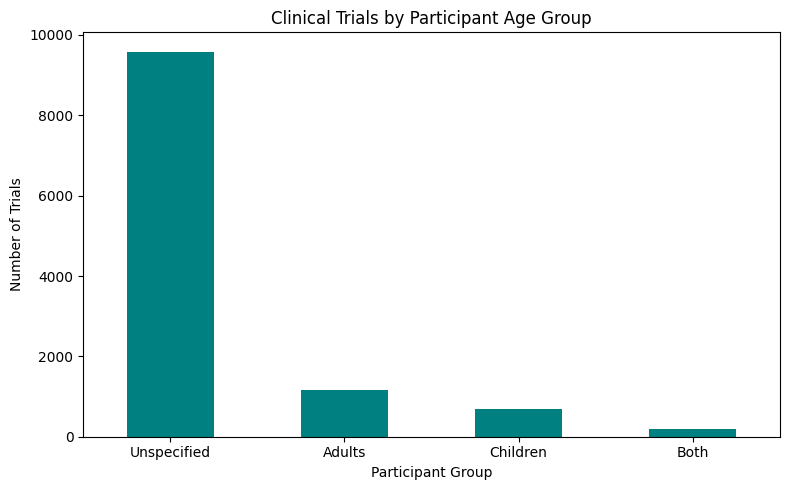

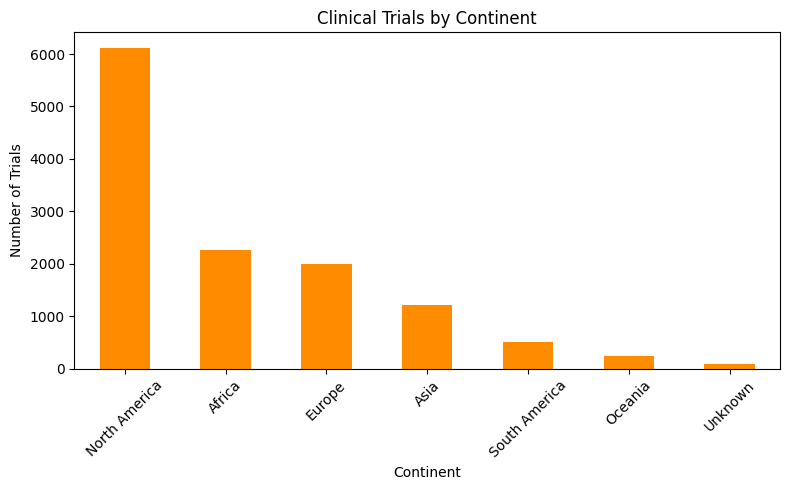

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the Excel file
excel_file = "hiv_clinical_trials_with_continents.xlsx"  # Update if your file has a different name

# Load the sheets
df_main = pd.read_excel(excel_file, sheet_name="Main_Metadata")
df_locations = pd.read_excel(excel_file, sheet_name="Locations_with_Continent")

# ------------------------------
# PART 1: Age Group Analysis (Adults vs Children)
# ------------------------------

def classify_age_group(text):
    text = str(text).lower()
    if "child" in text or "pediatric" in text:
        if "adult" in text:
            return "Both"
        return "Children"
    elif "adult" in text:
        return "Adults"
    else:
        return "Unspecified"

# Use Brief Summary or Description column to classify
df_main["Participant Group"] = df_main["Brief Summary"].apply(classify_age_group)

# Count groupings
age_group_counts = df_main["Participant Group"].value_counts()

# Plot age group distribution
plt.figure(figsize=(8, 5))
age_group_counts.plot(kind="bar", color="teal")
plt.title("Clinical Trials by Participant Age Group")
plt.xlabel("Participant Group")
plt.ylabel("Number of Trials")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ------------------------------
# PART 2: Continent Analysis
# ------------------------------

# Drop NaNs and duplicates for NCT ID + Continent
df_locations_clean = df_locations.dropna(subset=["Continent"])
df_locations_unique = df_locations_clean.drop_duplicates(subset=["NCT ID", "Continent"])

# Count unique trials per continent
continent_counts = df_locations_unique["Continent"].value_counts()

# Plot continent distribution
plt.figure(figsize=(8, 5))
continent_counts.plot(kind="bar", color="darkorange")
plt.title("Clinical Trials by Continent")
plt.xlabel("Continent")
plt.ylabel("Number of Trials")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


=== Clinical Trials by Continent ===
Continent
North America    6108
Africa           2258
Europe           1987
Asia             1224
South America     504
Oceania           241
Unknown            94
Name: count, dtype: int64

=== Clinical Trials by Participant Group ===
Participant Group
Unspecified    9587
Adults         1158
Children        697
Both            202
Name: count, dtype: int64

=== Clinical Trials per Year ===
Start Year
1981.0      1
1984.0      2
1985.0      1
1986.0      2
1987.0      1
1988.0      8
1989.0      6
1990.0      5
1991.0      2
1992.0      8
1993.0      3
1994.0     19
1995.0     19
1996.0     23
1997.0     37
1998.0     28
1999.0     81
2000.0     71
2001.0    107
2002.0    137
2003.0    201
2004.0    232
2005.0    285
2006.0    276
2007.0    310
2008.0    352
2009.0    426
2010.0    375
2011.0    408
2012.0    363
2013.0    337
2014.0    319
2015.0    355
2016.0    245
2017.0     28
2018.0     10
2019.0     15
2020.0     14
2021.0     18
2022.0     1

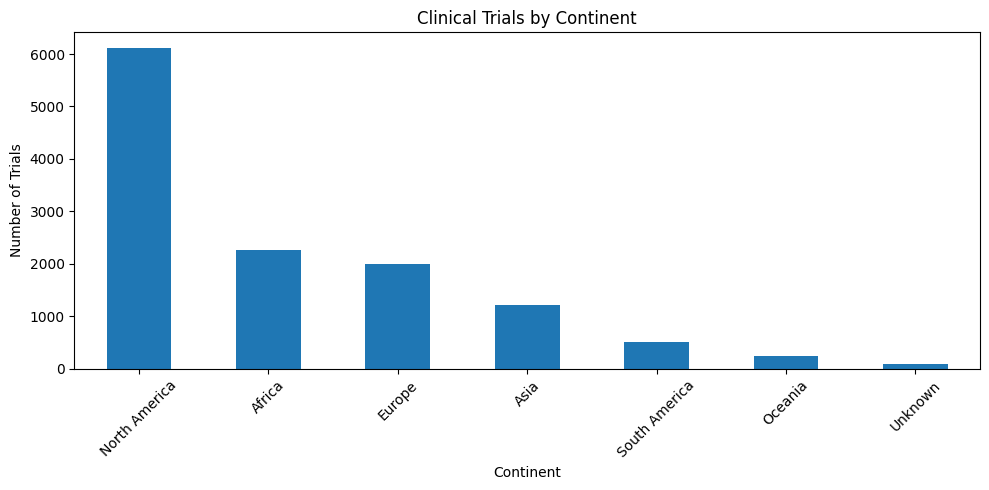

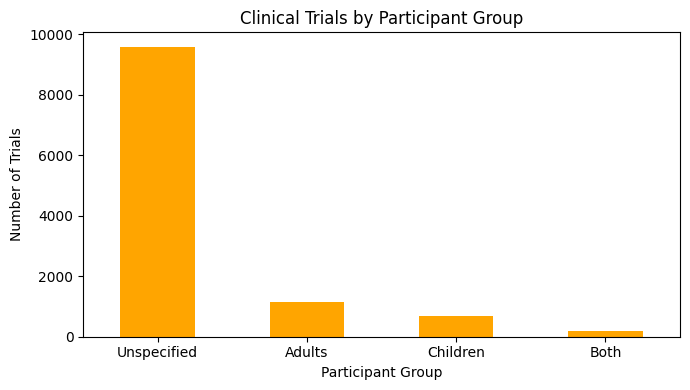

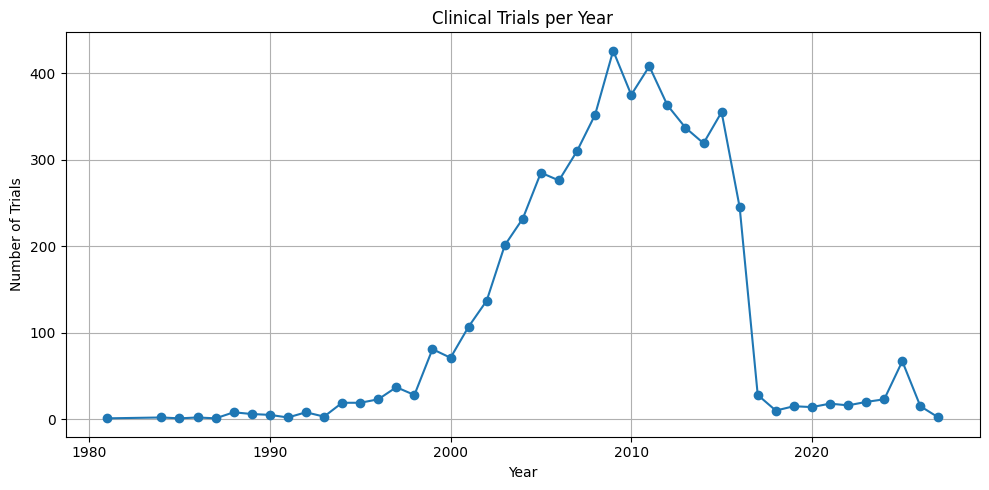

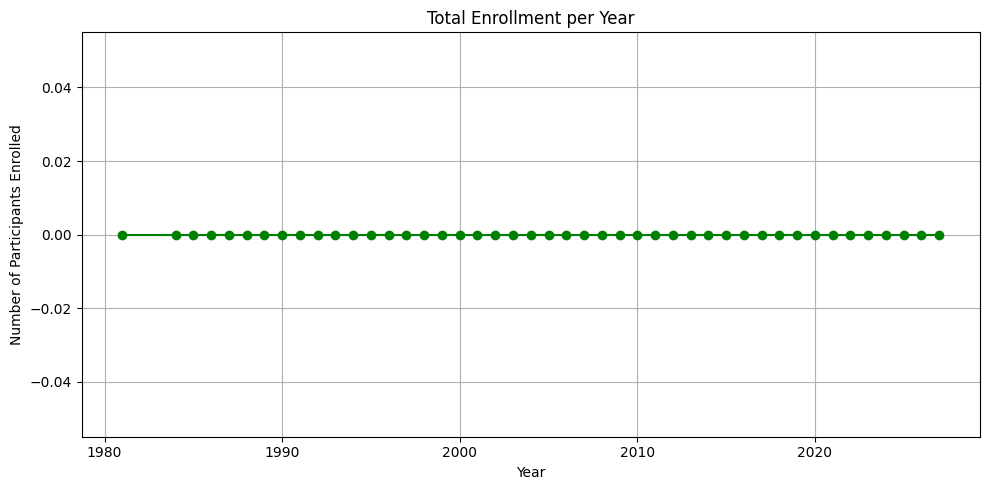

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load Excel file
excel_path = "hiv_clinical_trials_with_continents.xlsx"  # <-- Replace with your path if needed

# Load sheets
df_main = pd.read_excel(excel_path, sheet_name="Main_Metadata")
df_locations = pd.read_excel(excel_path, sheet_name="Locations_with_Continent")

# --- Clean and preprocess continent data ---
df_locations_clean = df_locations.dropna(subset=["Continent"])
df_locations_unique = df_locations_clean.drop_duplicates(subset=["NCT ID", "Continent"])
continent_counts = df_locations_unique["Continent"].value_counts().sort_values(ascending=False)

# --- Classify participant groups ---
def classify_age_group(text):
    text = str(text).lower()
    if "child" in text or "pediatric" in text:
        if "adult" in text:
            return "Both"
        return "Children"
    elif "adult" in text:
        return "Adults"
    else:
        return "Unspecified"

df_main["Participant Group"] = df_main["Brief Summary"].apply(classify_age_group)
age_group_counts = df_main["Participant Group"].value_counts().sort_values(ascending=False)

# --- Year-by-year count of clinical trials ---
df_main["Start Year"] = pd.to_datetime(df_main["Start Date"], errors="coerce").dt.year
trials_per_year = df_main["Start Year"].value_counts().sort_index()

# --- Year-by-year enrollment numbers ---
df_main["Enrollment"] = pd.to_numeric(df_main.get("Enrollment", "N/A"), errors="coerce")
enrollment_per_year = df_main.groupby("Start Year")["Enrollment"].sum().dropna()

# --- Display tables ---
print("=== Clinical Trials by Continent ===")
print(continent_counts)

print("\n=== Clinical Trials by Participant Group ===")
print(age_group_counts)

print("\n=== Clinical Trials per Year ===")
print(trials_per_year)

print("\n=== Total Enrollment per Year ===")
print(enrollment_per_year)

# --- Plotting ---

# 1. Clinical Trials by Continent
continent_counts.plot(kind='bar', figsize=(10, 5), title='Clinical Trials by Continent')
plt.xlabel("Continent")
plt.ylabel("Number of Trials")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Clinical Trials by Participant Group
age_group_counts.plot(kind='bar', figsize=(7, 4), title='Clinical Trials by Participant Group', color='orange')
plt.xlabel("Participant Group")
plt.ylabel("Number of Trials")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. Year-by-Year Clinical Trials
trials_per_year.plot(kind='line', marker='o', title='Clinical Trials per Year', figsize=(10, 5))
plt.xlabel("Year")
plt.ylabel("Number of Trials")
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Year-by-Year Enrollment
enrollment_per_year.plot(kind='line', marker='o', title='Total Enrollment per Year', color='green', figsize=(10, 5))
plt.xlabel("Year")
plt.ylabel("Number of Participants Enrolled")
plt.grid(True)
plt.tight_layout()
plt.show()



In [ ]:
import requests
import pandas as pd
import time

# --- Configuration ---
BASE_URL = "https://clinicaltrials.gov/api/v2/studies"
CONDITION = "HIV"
PAGE_SIZE = 100  # API max page size
MAX_RECORDS = 1000  # Limit to avoid timeout
SLEEP_BETWEEN_CALLS = 0.5  # seconds

# --- Containers ---
records = []

# --- Pagination Loop ---
offset = 0
while offset < MAX_RECORDS:
    params = {
        "query.condition": CONDITION,
        "fields": ",".join([
            "protocol_section.identification.nct_id",
            "protocol_section.status.overall_status",
            "protocol_section.sponsor.lead_sponsor.name",
            "protocol_section.eligibility.minimum_age",
            "protocol_section.eligibility.maximum_age",
            "protocol_section.eligibility.eligibility_criteria.textblock",
            "protocol_section.status.start_date"
        ]),
        "pageSize": PAGE_SIZE,
        "pageToken": str(offset)
    }

    response = requests.get(BASE_URL, params=params)
    if response.status_code != 200:
        print(f"Failed request at offset {offset}. Status code: {response.status_code}")
        break

    data = response.json()
    studies = data.get("studies", [])
    if not studies:
        break

    # Extract needed fields
    for study in studies:
        protocol = study.get("protocol_section", {})
        identification = protocol.get("identification", {})
        eligibility = protocol.get("eligibility", {})
        sponsor = protocol.get("sponsor", {})
        status = protocol.get("status", {})

        records.append({
            "NCT ID": identification.get("nct_id"),
            "Status": status.get("overall_status"),
            "Sponsor": sponsor.get("lead_sponsor", {}).get("name"),
            "Start Date": status.get("start_date"),
            "Min Age": eligibility.get("minimum_age"),
            "Max Age": eligibility.get("maximum_age"),
            "Eligibility Text": eligibility.get("eligibility_criteria", {}).get("textblock")
        })

    offset += PAGE_SIZE
    time.sleep(SLEEP_BETWEEN_CALLS)

# --- Convert to DataFrame and Save ---
df = pd.DataFrame(records)
print(df.head())
df.to_csv("hiv_trials_with_age.csv", index=False)


Failed request at offset 0. Status code: 400
Empty DataFrame
Columns: []
Index: []


In [ ]:
import requests
import json
import pandas as pd

# -------------------------------
# Step 1: Fetch HIV Clinical Trials Data
# -------------------------------
BASE_URL = "https://clinicaltrials.gov/api/v2/studies"
page_size = 100
page_token = None
all_studies = []

print("🔄 Fetching all HIV clinical trial data...")

while True:
    params = {
        "query.term": "HIV",
        "pageSize": page_size
    }
    if page_token:
        params["pageToken"] = page_token

    response = requests.get(BASE_URL, params=params)
    if response.status_code != 200:
        print(f"❌ Failed to fetch data. Status code: {response.status_code}")
        break

    data = response.json()
    studies = data.get("studies", [])
    all_studies.extend(studies)

    print(f"✅ Fetched {len(all_studies)} studies so far...")

    page_token = data.get("nextPageToken")
    if not page_token:
        break

print(f"🎉 Finished fetching! Total studies: {len(all_studies)}")

# -------------------------------
# Step 2: Save Raw JSON
# -------------------------------
json_file = "hiv_clinical_trials_full_raw.json"
with open(json_file, "w") as f:
    json.dump(all_studies, f, indent=4)
print(f"💾 Raw JSON saved as '{json_file}'")

# -------------------------------
# Step 3: Convert to Fully Exploded Excel
# -------------------------------
main_data = []
interventions_data = []
locations_data = []
outcomes_data = []
serious_adverse_data = []
other_adverse_data = []

for study in all_studies:
    protocol = study.get("protocolSection", {})
    results = study.get("resultsSection", {})
    eligibility = protocol.get("eligibilityModule", {})
    nct_id = protocol.get("identificationModule", {}).get("nctId", "N/A")

    # --- Main Metadata ---
    main_data.append({
        "NCT ID": nct_id,
        "Brief Title": protocol.get("identificationModule", {}).get("briefTitle", "N/A"),
        "Official Title": protocol.get("identificationModule", {}).get("officialTitle", "N/A"),
        "Study Type": protocol.get("designModule", {}).get("studyType", "N/A"),
        "Phase": protocol.get("designModule", {}).get("phase", "N/A"),
        "Overall Status": protocol.get("statusModule", {}).get("overallStatus", "N/A"),
        "Start Date": protocol.get("statusModule", {}).get("startDateStruct", {}).get("date", "N/A"),
        "Primary Completion Date": protocol.get("statusModule", {}).get("primaryCompletionDateStruct", {}).get("date", "N/A"),
        "Completion Date": protocol.get("statusModule", {}).get("completionDateStruct", {}).get("date", "N/A"),
        "Sponsor": protocol.get("sponsorCollaboratorsModule", {}).get("leadSponsor", {}).get("name", "N/A"),
        "Collaborators": "; ".join([col.get("name","N/A") for col in protocol.get("sponsorCollaboratorsModule", {}).get("collaborators", [])]) or "N/A",
        "Brief Summary": protocol.get("descriptionModule", {}).get("briefSummary", "N/A"),

        # ✅ NEW AGE-RELATED FIELDS
        "Minimum Age": eligibility.get("minimumAge", "N/A"),
        "Maximum Age": eligibility.get("maximumAge", "N/A"),
        "Eligibility Criteria": eligibility.get("eligibilityCriteria", {}).get("textblock", "N/A")
    })

    # --- Interventions ---
    for iv in protocol.get("armsInterventionsModule", {}).get("interventions", []):
        interventions_data.append({
            "NCT ID": nct_id,
            "Intervention Name": iv.get("name", "N/A"),
            "Type": iv.get("type", "N/A"),
            "Description": iv.get("description", "N/A")
        })

    # --- Locations ---
    for loc in protocol.get("contactsLocationsModule", {}).get("locations", []):
        locations_data.append({
            "NCT ID": nct_id,
            "Facility": loc.get("locationFacility", "N/A"),
            "City": loc.get("city", "N/A"),
            "State": loc.get("state", "N/A"),
            "Country": loc.get("country", "N/A")
        })

    # --- Outcomes ---
    outcomes_module = results.get("outcomesModule", {})
    for outcome in outcomes_module.get("primaryOutcomes", []):
        outcomes_data.append({
            "NCT ID": nct_id,
            "Type": "Primary",
            "Measure": outcome.get("measure", "N/A"),
            "Time Frame": outcome.get("timeFrame", "N/A"),
            "Description": outcome.get("description", "N/A")
        })
    for outcome in outcomes_module.get("secondaryOutcomes", []):
        outcomes_data.append({
            "NCT ID": nct_id,
            "Type": "Secondary",
            "Measure": outcome.get("measure", "N/A"),
            "Time Frame": outcome.get("timeFrame", "N/A"),
            "Description": outcome.get("description", "N/A")
        })

    # --- Adverse Events ---
    ae_module = results.get("adverseEventsModule", {})
    for event in ae_module.get("seriousEvents", []):
        serious_adverse_data.append({
            "NCT ID": nct_id,
            "Event Term": event.get("term", "N/A"),
            "Organ System": event.get("organSystem", "N/A"),
            "Frequency Threshold": ae_module.get("frequencyThreshold", "N/A")
        })
    for event in ae_module.get("otherEvents", []):
        other_adverse_data.append({
            "NCT ID": nct_id,
            "Event Term": event.get("term", "N/A"),
            "Organ System": event.get("organSystem", "N/A"),
            "Frequency Threshold": ae_module.get("frequencyThreshold", "N/A")
        })

# Convert lists to DataFrames
df_main = pd.DataFrame(main_data).fillna("N/A")
df_interventions = pd.DataFrame(interventions_data).fillna("N/A")
df_locations = pd.DataFrame(locations_data).fillna("N/A")
df_outcomes = pd.DataFrame(outcomes_data).fillna("N/A")
df_serious_ae = pd.DataFrame(serious_adverse_data).fillna("N/A")
df_other_ae = pd.DataFrame(other_adverse_data).fillna("N/A")

# Save to Excel with multiple sheets
output_file = "hiv_clinical_trials_full_exploded.xlsx"
with pd.ExcelWriter(output_file, engine="xlsxwriter") as writer:
    df_main.to_excel(writer, sheet_name="Main_Metadata", index=False)
    df_interventions.to_excel(writer, sheet_name="Interventions", index=False)
    df_locations.to_excel(writer, sheet_name="Locations", index=False)
    df_outcomes.to_excel(writer, sheet_name="Outcomes", index=False)
    df_serious_ae.to_excel(writer, sheet_name="Serious_AdverseEvents", index=False)
    df_other_ae.to_excel(writer, sheet_name="Other_AdverseEvents", index=False)

print(f"💾 Full dataset saved as '{output_file}' with 6 sheets.")


🔄 Fetching all HIV clinical trial data...
✅ Fetched 100 studies so far...
✅ Fetched 200 studies so far...
✅ Fetched 300 studies so far...
✅ Fetched 400 studies so far...
✅ Fetched 500 studies so far...
✅ Fetched 600 studies so far...
✅ Fetched 700 studies so far...
✅ Fetched 800 studies so far...
✅ Fetched 900 studies so far...
✅ Fetched 1000 studies so far...
✅ Fetched 1100 studies so far...
✅ Fetched 1200 studies so far...
✅ Fetched 1300 studies so far...
✅ Fetched 1400 studies so far...
✅ Fetched 1500 studies so far...
✅ Fetched 1600 studies so far...
✅ Fetched 1700 studies so far...
✅ Fetched 1800 studies so far...
✅ Fetched 1900 studies so far...
✅ Fetched 2000 studies so far...
✅ Fetched 2100 studies so far...
✅ Fetched 2200 studies so far...
✅ Fetched 2300 studies so far...
✅ Fetched 2400 studies so far...
✅ Fetched 2500 studies so far...
✅ Fetched 2600 studies so far...
✅ Fetched 2700 studies so far...
✅ Fetched 2800 studies so far...
✅ Fetched 2900 studies so far...
✅ Fetched 

AttributeError: 'str' object has no attribute 'get'

In [ ]:
import requests
import json
import pandas as pd

# -------------------------------
# Step 1: Fetch HIV Clinical Trials Data
# -------------------------------
BASE_URL = "https://clinicaltrials.gov/api/v2/studies"
page_size = 100
page_token = None
all_studies = []

print("🔄 Fetching all HIV clinical trial data...")

while True:
    params = {
        "query.term": "HIV",
        "pageSize": page_size
    }
    if page_token:
        params["pageToken"] = page_token

    response = requests.get(BASE_URL, params=params)
    if response.status_code != 200:
        print(f"❌ Failed to fetch data. Status code: {response.status_code}")
        break

    data = response.json()
    studies = data.get("studies", [])
    all_studies.extend(studies)

    print(f"✅ Fetched {len(all_studies)} studies so far...")

    page_token = data.get("nextPageToken")
    if not page_token:
        break

print(f"🎉 Finished fetching! Total studies: {len(all_studies)}")

# -------------------------------
# Step 2: Save Raw JSON
# -------------------------------
json_file = "hiv_clinical_trials_full_raw.json"
with open(json_file, "w") as f:
    json.dump(all_studies, f, indent=4)
print(f"💾 Raw JSON saved as '{json_file}'")

# -------------------------------
# Step 3: Convert to Fully Exploded Excel
# -------------------------------
main_data = []
interventions_data = []
locations_data = []
outcomes_data = []
serious_adverse_data = []
other_adverse_data = []

for study in all_studies:
    protocol = study.get("protocolSection", {})
    results = study.get("resultsSection", {})
    nct_id = protocol.get("identificationModule", {}).get("nctId", "N/A")
    eligibility = protocol.get("eligibilityModule", {})

    # Handle eligibility criteria that may be dict or str
    eligibility_criteria = eligibility.get("eligibilityCriteria", "N/A")
    if isinstance(eligibility_criteria, dict):
        eligibility_criteria = eligibility_criteria.get("textblock", "N/A")

    # --- Main Metadata ---
    main_data.append({
        "NCT ID": nct_id,
        "Brief Title": protocol.get("identificationModule", {}).get("briefTitle", "N/A"),
        "Official Title": protocol.get("identificationModule", {}).get("officialTitle", "N/A"),
        "Study Type": protocol.get("designModule", {}).get("studyType", "N/A"),
        "Phase": protocol.get("designModule", {}).get("phase", "N/A"),
        "Overall Status": protocol.get("statusModule", {}).get("overallStatus", "N/A"),
        "Start Date": protocol.get("statusModule", {}).get("startDateStruct", {}).get("date", "N/A"),
        "Primary Completion Date": protocol.get("statusModule", {}).get("primaryCompletionDateStruct", {}).get("date", "N/A"),
        "Completion Date": protocol.get("statusModule", {}).get("completionDateStruct", {}).get("date", "N/A"),
        "Sponsor": protocol.get("sponsorCollaboratorsModule", {}).get("leadSponsor", {}).get("name", "N/A"),
        "Collaborators": "; ".join([col.get("name", "N/A") for col in protocol.get("sponsorCollaboratorsModule", {}).get("collaborators", [])]) or "N/A",
        "Brief Summary": protocol.get("descriptionModule", {}).get("briefSummary", "N/A"),
        "Minimum Age": eligibility.get("minimumAge", "N/A"),
        "Maximum Age": eligibility.get("maximumAge", "N/A"),
        "Eligibility Criteria": eligibility_criteria
    })

    # --- Interventions ---
    for iv in protocol.get("armsInterventionsModule", {}).get("interventions", []):
        interventions_data.append({
            "NCT ID": nct_id,
            "Intervention Name": iv.get("name", "N/A"),
            "Type": iv.get("type", "N/A"),
            "Description": iv.get("description", "N/A")
        })

    # --- Locations ---
    for loc in protocol.get("contactsLocationsModule", {}).get("locations", []):
        locations_data.append({
            "NCT ID": nct_id,
            "Facility": loc.get("locationFacility", "N/A"),
            "City": loc.get("city", "N/A"),
            "State": loc.get("state", "N/A"),
            "Country": loc.get("country", "N/A")
        })

    # --- Outcomes ---
    outcomes_module = results.get("outcomesModule", {})
    for outcome in outcomes_module.get("primaryOutcomes", []):
        outcomes_data.append({
            "NCT ID": nct_id,
            "Type": "Primary",
            "Measure": outcome.get("measure", "N/A"),
            "Time Frame": outcome.get("timeFrame", "N/A"),
            "Description": outcome.get("description", "N/A")
        })
    for outcome in outcomes_module.get("secondaryOutcomes", []):
        outcomes_data.append({
            "NCT ID": nct_id,
            "Type": "Secondary",
            "Measure": outcome.get("measure", "N/A"),
            "Time Frame": outcome.get("timeFrame", "N/A"),
            "Description": outcome.get("description", "N/A")
        })

    # --- Adverse Events ---
    ae_module = results.get("adverseEventsModule", {})
    for event in ae_module.get("seriousEvents", []):
        serious_adverse_data.append({
            "NCT ID": nct_id,
            "Event Term": event.get("term", "N/A"),
            "Organ System": event.get("organSystem", "N/A"),
            "Frequency Threshold": ae_module.get("frequencyThreshold", "N/A")
        })
    for event in ae_module.get("otherEvents", []):
        other_adverse_data.append({
            "NCT ID": nct_id,
            "Event Term": event.get("term", "N/A"),
            "Organ System": event.get("organSystem", "N/A"),
            "Frequency Threshold": ae_module.get("frequencyThreshold", "N/A")
        })

# Convert lists to DataFrames
df_main = pd.DataFrame(main_data).fillna("N/A")
df_interventions = pd.DataFrame(interventions_data).fillna("N/A")
df_locations = pd.DataFrame(locations_data).fillna("N/A")
df_outcomes = pd.DataFrame(outcomes_data).fillna("N/A")
df_serious_ae = pd.DataFrame(serious_adverse_data).fillna("N/A")
df_other_ae = pd.DataFrame(other_adverse_data).fillna("N/A")

# Save to Excel with multiple sheets
output_file = "hiv_clinical_trials_full_exp.xlsx"
with pd.ExcelWriter(output_file, engine="xlsxwriter") as writer:
    df_main.to_excel(writer, sheet_name="Main_Metadata", index=False)
    df_interventions.to_excel(writer, sheet_name="Interventions", index=False)
    df_locations.to_excel(writer, sheet_name="Locations", index=False)
    df_outcomes.to_excel(writer, sheet_name="Outcomes", index=False)
    df_serious_ae.to_excel(writer, sheet_name="Serious_AdverseEvents", index=False)
    df_other_ae.to_excel(writer, sheet_name="Other_AdverseEvents", index=False)

print(f"💾 Full dataset saved as '{output_file}' with 6 sheets.")


🔄 Fetching all HIV clinical trial data...
✅ Fetched 100 studies so far...
✅ Fetched 200 studies so far...
✅ Fetched 300 studies so far...
✅ Fetched 400 studies so far...
✅ Fetched 500 studies so far...
✅ Fetched 600 studies so far...
✅ Fetched 700 studies so far...
✅ Fetched 800 studies so far...
✅ Fetched 900 studies so far...
✅ Fetched 1000 studies so far...
✅ Fetched 1100 studies so far...
✅ Fetched 1200 studies so far...
✅ Fetched 1300 studies so far...
✅ Fetched 1400 studies so far...
✅ Fetched 1500 studies so far...
✅ Fetched 1600 studies so far...
✅ Fetched 1700 studies so far...
✅ Fetched 1800 studies so far...
✅ Fetched 1900 studies so far...
✅ Fetched 2000 studies so far...
✅ Fetched 2100 studies so far...
✅ Fetched 2200 studies so far...
✅ Fetched 2300 studies so far...
✅ Fetched 2400 studies so far...
✅ Fetched 2500 studies so far...
✅ Fetched 2600 studies so far...
✅ Fetched 2700 studies so far...
✅ Fetched 2800 studies so far...
✅ Fetched 2900 studies so far...
✅ Fetched 

In [ ]:
import requests
import pandas as pd

def fetch_all_hiv_trials():
    url = "https://clinicaltrials.gov/api/v2/studies"
    params = {
        "query.term": "HIV",
        "pageSize": 1000,
        "format": "json"
    }

    all_studies = []
    next_page_token = None

    while True:
        if next_page_token:
            params["pageToken"] = next_page_token
        response = requests.get(url, params=params)
        response.raise_for_status()
        data = response.json()

        studies = data.get("studies", [])
        all_studies.extend(studies)

        next_page_token = data.get("nextPageToken")
        if not next_page_token:
            break

    return all_studies

def convert_to_dataframe_v2(studies):
    records = []
    for study in studies:
        record = {
            "NCTId": study.get("protocolSection", {}).get("identificationModule", {}).get("nctId"),
            "BriefTitle": study.get("protocolSection", {}).get("identificationModule", {}).get("briefTitle"),
            "Condition": ", ".join(study.get("protocolSection", {}).get("conditionsModule", {}).get("conditions", [])),
            "StudyType": study.get("protocolSection", {}).get("designModule", {}).get("studyType"),
            "Gender": study.get("protocolSection", {}).get("eligibilityModule", {}).get("gender"),
            "MinimumAge": study.get("protocolSection", {}).get("eligibilityModule", {}).get("minimumAge"),
            "MaximumAge": study.get("protocolSection", {}).get("eligibilityModule", {}).get("maximumAge"),
            "LocationCountry": ", ".join([
                loc.get("country") for loc in study.get("protocolSection", {}).get("contactsLocationsModule", {}).get("locations", [])
                if loc.get("country")
            ]),
            "Phase": study.get("protocolSection", {}).get("designModule", {}).get("phase"),
            "EnrollmentCount": study.get("protocolSection", {}).get("designModule", {}).get("enrollment"),
            "StartDate": study.get("protocolSection", {}).get("statusModule", {}).get("startDateStruct", {}).get("date")
        }
        records.append(record)
    return pd.DataFrame(records)

def summarize_data(df):
    print("📊 Summary of HIV Clinical Trials Data")
    print(f"Total trials retrieved: {len(df)}\n")

    print("🧬 Trials by Gender:")
    print(df["Gender"].value_counts(dropna=False), "\n")

    print("🧪 Trials by Phase:")
    print(df["Phase"].value_counts(dropna=False), "\n")

    print("🌍 Trials by Country:")
    country_counts = df["LocationCountry"].str.split(", ").explode().value_counts()
    print(country_counts.head(10), "\n")

    print("📅 Trials by Start Year:")
    df["StartYear"] = pd.to_datetime(df["StartDate"], errors='coerce').dt.year
    print(df["StartYear"].value_counts().sort_index(), "\n")

def export_to_excel(df, filename="HIV_Clinical_Trials_All.xlsx"):
    with pd.ExcelWriter(filename, engine='openpyxl') as writer:
        df.to_excel(writer, sheet_name="All_Trials", index=False)
        df[["NCTId", "BriefTitle", "MinimumAge", "MaximumAge"]].to_excel(writer, sheet_name="By_Age", index=False)
        df[["NCTId", "BriefTitle", "Gender"]].to_excel(writer, sheet_name="By_Gender", index=False)
        df[["NCTId", "BriefTitle", "LocationCountry"]].to_excel(writer, sheet_name="By_Country", index=False)
        df[["NCTId", "BriefTitle", "Phase"]].to_excel(writer, sheet_name="By_Phase", index=False)

if __name__ == "__main__":
    hiv_trials = fetch_all_hiv_trials()
    df = convert_to_dataframe_v2(hiv_trials)
    export_to_excel(df)
    summarize_data(df)

    print("✅ All HIV clinical trials exported to 'HIV_Clinical_Trials_All.xlsx'")



📊 Summary of HIV Clinical Trials Data
Total trials retrieved: 11644

🧬 Trials by Gender:
Gender
None    11644
Name: count, dtype: int64 

🧪 Trials by Phase:
Phase
None    11644
Name: count, dtype: int64 

🌍 Trials by Country:
LocationCountry
United States     40544
France             3637
Spain              3323
South Africa       2705
Germany            2331
Canada             1778
Italy              1703
United Kingdom     1495
Thailand           1195
Australia          1076
Name: count, dtype: int64 

📅 Trials by Start Year:
StartYear
1981.0      1
1984.0      2
1985.0      1
1986.0      2
1987.0      1
1988.0      8
1989.0      6
1990.0      5
1991.0      2
1992.0      8
1993.0      3
1994.0     19
1995.0     19
1996.0     23
1997.0     37
1998.0     28
1999.0     81
2000.0     71
2001.0    107
2002.0    137
2003.0    201
2004.0    232
2005.0    285
2006.0    276
2007.0    310
2008.0    352
2009.0    426
2010.0    375
2011.0    408
2012.0    363
2013.0    337
2014.0    319
2015.0  

In [ ]:
import requests
import json
import pandas as pd

BASE_URL = "https://clinicaltrials.gov/api/v2/studies"
PAGE_SIZE = 50  # max 100, but smaller per-call JSON ensures manageability
page_token = None
all_studies = []

print("Fetching full HIV trial data with all JSON fields...")

while True:
    params = {
        "query.term": "HIV",
        "pageSize": PAGE_SIZE,
        # No fields parameter: this retrieves *all* data available in JSON structure
    }
    if page_token:
        params["pageToken"] = page_token

    resp = requests.get(BASE_URL, params=params)
    if resp.status_code != 200:
        print("Error:", resp.status_code)
        break

    json_data = resp.json()
    all_studies.extend(json_data.get("studies", []))
    page_token = json_data.get("nextPageToken")
    print(f"Collected {len(all_studies)} trials so far...")
    if not page_token:
        break

print("Done fetching all full JSON data.")

# Save full JSON for inspection
with open("hiv_full_raw_all_fields.json", "w") as f:
    json.dump(all_studies, f, indent=2)
print("Saved full raw JSON file.")

# Now normalize and flatten JSON to Excel:

# Convert list of study dicts into pandas DataFrame,
# using json_normalize to deeply flatten nested JSON.
df_full = pd.json_normalize(all_studies, sep="_")

output_excel = "hiv_full_all_fields.xlsx"
df_full.to_excel(output_excel, index=False)
print(f"Saved full flattened data to {output_excel}")


Fetching full HIV trial data with all JSON fields...
Collected 50 trials so far...
Collected 100 trials so far...
Collected 150 trials so far...
Collected 200 trials so far...
Collected 250 trials so far...
Collected 300 trials so far...
Collected 350 trials so far...
Collected 400 trials so far...
Collected 450 trials so far...
Collected 500 trials so far...
Collected 550 trials so far...
Collected 600 trials so far...
Collected 650 trials so far...
Collected 700 trials so far...
Collected 750 trials so far...
Collected 800 trials so far...
Collected 850 trials so far...
Collected 900 trials so far...
Collected 950 trials so far...
Collected 1000 trials so far...
Collected 1050 trials so far...
Collected 1100 trials so far...
Collected 1150 trials so far...
Collected 1200 trials so far...
Collected 1250 trials so far...
Collected 1300 trials so far...
Collected 1350 trials so far...
Collected 1400 trials so far...
Collected 1450 trials so far...
Collected 1500 trials so far...
Collect